# Lab: Data Visualization and Visual Thinking

The U.S. Bureau of Transportation Statistics collects information about scheduled domestic flights. In this lab, you will use the ideas from **Data Visualization and Visual Thinking** to examine a documented sample of 5,000 completed, non-diverted flights from May 2026.


## Learning goals

By the end of this lab, you should be able to:

- load and inspect a CSV file as a Pandas DataFrame;
- distinguish Pandas data types from quantitative and categorical feature types;
- check for missing values;
- create and label a histogram and a bar chart;
- describe a distribution by its typical values, range, and skew;
- use `.describe()` to check estimates made from a histogram;
- explain how histogram bins and axis scales affect a figure; and
- identify conclusions that can and cannot be supported by a sample; and
- find a documented dataset, audit every feature, and interpret its quantitative and categorical distributions.


## Using AI tools responsibly

You may use an AI tool to ask questions, debug code, or receive feedback. You are still responsible for understanding every part of your submission and checking suggestions against your notebook's output. At the end of the lab, disclose whether you used an AI tool and how you evaluated its advice.


## Dataset

The [U.S. Bureau of Transportation Statistics (BTS) Reporting Carrier On-Time Performance data](https://www.transtats.bts.gov/DL_SelectFields.aspx?QO_fu146_anzr=b0-gvzr&gnoyr_VQ=FGJ) contains 611,735 reported domestic flight records for May 2026. Completed, non-diverted flights with recorded values for all five selected features were eligible for this lab. Canceled flights, diverted flights, and records missing any selected feature were excluded before the sample was drawn.

The dataset is a reproducible random sample of 5,000 eligible flights. Each observation represents one completed, non-diverted domestic flight in that sample. Because incomplete records were removed before sampling, finding no missing values in the dataset does not mean that the original BTS data had no missing values. Conclusions from this sample describe the eligible flights and should not automatically be generalized to canceled or diverted flights.

| Feature | Description |
| --- | --- |
| `airline` | Airline that reported the flight |
| `origin_city` | Departure city |
| `destination_city` | Arrival city |
| `distance_miles` | Nonstop flight distance in miles |
| `arrival_delay_minutes` | Minutes between scheduled and actual arrival; negative values mean the flight arrived early |


## Load and preview the data

Import Pandas using the conventional alias `pd`. Read `data/bts_flights_may_2026_sample.csv` into a DataFrame named `flights`.


In [14]:
import pandas as pd


flights = pd.read_csv("data/bts_flights_may_2026_sample.csv")

Display the first five rows of the DataFrame.


In [12]:
flights.head()

,airline,origin_city,destination_city,distance_miles,arrival_delay_minutes
0,Alaska Airlines,"Anchorage, AK","Chicago, IL",2846,65
1,Alaska Airlines,"Anchorage, AK","Cordova, AK",160,-1
2,Alaska Airlines,"Anchorage, AK","Fairbanks, AK",261,-18
3,Alaska Airlines,"Anchorage, AK","Juneau, AK",571,-21
4,Alaska Airlines,"Anchorage, AK","Juneau, AK",571,-14


Display the last five rows of the DataFrame.


In [11]:
flights.tail()

,airline,origin_city,destination_city,distance_miles,arrival_delay_minutes
4995,United Airlines,"West Palm Beach/Palm Beach, FL","Chicago, IL",1144,0
4996,United Airlines,"West Palm Beach/Palm Beach, FL","Houston, TX",956,-22
4997,United Airlines,"West Palm Beach/Palm Beach, FL","Houston, TX",956,-29
4998,United Airlines,"West Palm Beach/Palm Beach, FL","Newark, NJ",1024,-26
4999,United Airlines,"West Palm Beach/Palm Beach, FL","Newark, NJ",1024,7


## Inspect the DataFrame

Display a summary of the DataFrame that includes the feature names, the number of non-missing values, and the Pandas data types.


In [16]:
flights.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   airline                5000 non-null   object
 1   origin_city            5000 non-null   object
 2   destination_city       5000 non-null   object
 3   distance_miles         5000 non-null   int64 
 4   arrival_delay_minutes  5000 non-null   int64 
dtypes: int64(2), object(3)
memory usage: 195.4+ KB


**How many observations are in the DataFrame?**

Your answer:3


Count the missing values in every feature.


In [19]:
flights.isnull().sum()

airline                  0
origin_city              0
destination_city         0
distance_miles           0
arrival_delay_minutes    0
dtype: int64

## Classify the features

A **quantitative feature** records an amount or measurement for which arithmetic is meaningful. A **categorical feature** assigns observations to groups or labels.


**Complete the table with the Pandas data type, feature type, and number of missing values for each feature. Use `.info()` and `.isnull().sum()`; enter 0 when no values are missing.**

| Feature | Pandas data type | Feature type | Number of missing values |
| --- | --- | --- | ---: |
| `airline` | object | 5000 non-null | 0 |
| `origin_city` | object |5000 non-null  | 0 |
| `destination_city` |  object| 5000 non-null | 0 |
| `distance_miles` | int | 5000 non-null | 0 |
| `arrival_delay_minutes` | int | 5000 non-null | 0 |


## Which destination city is most common in the sample?

Calculate and display the frequency of each destination city. Save the result as `destination_counts`.


In [25]:
import matplotlib.pyplot as plt

flights.head(10)


,airline,origin_city,destination_city,distance_miles,arrival_delay_minutes
0,Alaska Airlines,"Anchorage, AK","Chicago, IL",2846,65
1,Alaska Airlines,"Anchorage, AK","Cordova, AK",160,-1
2,Alaska Airlines,"Anchorage, AK","Fairbanks, AK",261,-18
3,Alaska Airlines,"Anchorage, AK","Juneau, AK",571,-21
4,Alaska Airlines,"Anchorage, AK","Juneau, AK",571,-14
5,Alaska Airlines,"Anchorage, AK","Kodiak, AK",253,-8
6,Alaska Airlines,"Anchorage, AK","Kodiak, AK",253,-18
7,Alaska Airlines,"Anchorage, AK","Kodiak, AK",253,9
8,Alaska Airlines,"Anchorage, AK","Los Angeles, CA",2345,-15
9,Alaska Airlines,"Anchorage, AK","Los Angeles, CA",2345,-44


Import `matplotlib.pyplot` using the conventional alias `plt`. Use `.head(10)` on `destination_counts` to select the ten most frequent destination cities, then create a bar chart. Give the figure a descriptive title and label both axes.


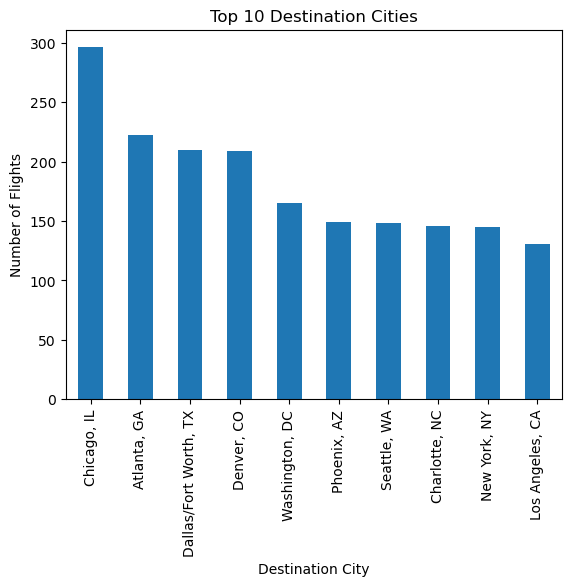

In [52]:
top_destinations = flights["destination_city"].value_counts().head(10)

top_destinations.plot(kind="bar")

plt.title("Top 10 Destination Cities")
plt.xlabel("Destination City")
plt.ylabel("Number of Flights")
plt.show()

**Which destination city is most common in the sample?**

Your answer: Chicago, IL


## What was the distribution of arrival delays?

Negative values represent early arrivals, zero represents an on-time arrival, and positive values represent late arrivals.

Create a histogram of `arrival_delay_minutes` using the default number of bins. Give the figure a descriptive title and label both axes.


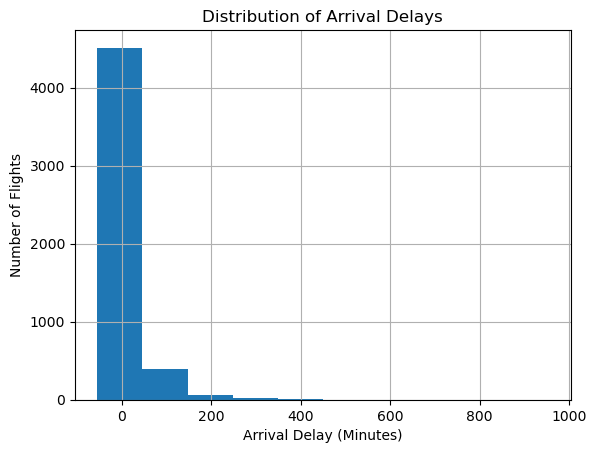

In [53]:
flights["arrival_delay_minutes"].hist()

plt.title("Distribution of Arrival Delays")
plt.xlabel("Arrival Delay (Minutes)")
plt.ylabel("Number of Flights")

plt.show()

**Approximately what arrival-delay value appears most common?**

Your answer: 0


**What is the approximate range from the smallest to the largest arrival-delay value?**

Your answer: 365 minutes


**Does the arrival-delay distribution appear symmetric or skewed?**

Your answer: the arrival-delay distribution is skewed


Display a numerical summary of `arrival_delay_minutes`.


In [55]:
flights["arrival_delay_minutes"].describe()


count    5000.000000
mean        6.098800
std        48.335493
min       -55.000000
25%       -16.000000
50%        -6.000000
75%        10.000000
max       953.000000
Name: arrival_delay_minutes, dtype: float64

Calculate and display the exact mode of `arrival_delay_minutes` using `.mode()`.


In [56]:
flights["arrival_delay_minutes"].mode()

0   -8
Name: arrival_delay_minutes, dtype: int64

**How closely did the calculated mode match the most common value you estimated from the histogram?**

Your answer: very close


**How closely did the minimum and maximum from `.describe()` match the range you estimated from the histogram?**

Your answer: very close


**Is the mean greater than, less than, or approximately equal to the median?**

Your answer:the mean arrival delay (6.10 minutes) is greater than the median (−6 minutes).


**How is the relationship between the mean and median connected to the histogram's shape?**

Your answer:Most flights had arrival delays clustered near zero or slightly negative values, but a small number of flights experienced very large delays; the extreme positive delays create a long right tail that pulls the mean upward more than the median


## Applying the principles: histogram bins

Re-create the arrival-delay histogram using exactly 5 bins.


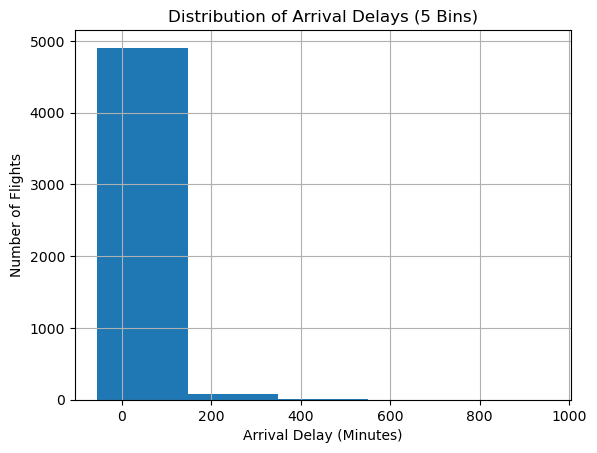

In [57]:
flights["arrival_delay_minutes"].hist(bins=5)

plt.title("Distribution of Arrival Delays (5 Bins)")
plt.xlabel("Arrival Delay (Minutes)")
plt.ylabel("Number of Flights")

plt.show()

Re-create the arrival-delay histogram using exactly 25 bins.


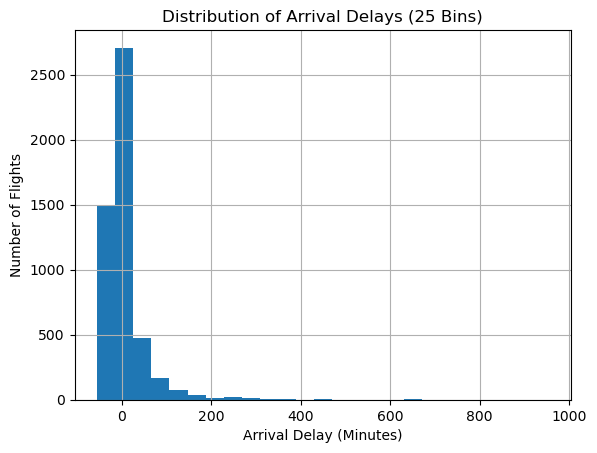

In [58]:
flights["arrival_delay_minutes"].hist(bins=25)

plt.title("Distribution of Arrival Delays (25 Bins)")
plt.xlabel("Arrival Delay (Minutes)")
plt.ylabel("Number of Flights")

plt.show()

**What changed when the number of bins was reduced to 5?**

Your answer:When the number of bins was reduced to 5, the histogram became much less detailed because a wider range of arrival-delay values was grouped into each bar


**What changed when the number of bins was increased to 25?**

Your answer:When the number of bins was increased to 25, the histogram showed much more detail because the data were divided into smaller intervals.


**Which bin setting communicates the distribution most clearly?**

Your answer:The 25-bin histogram communicates the distribution most clearly


## Applying the principles: a misleading vertical axis

Run both cells below and compare the figures.


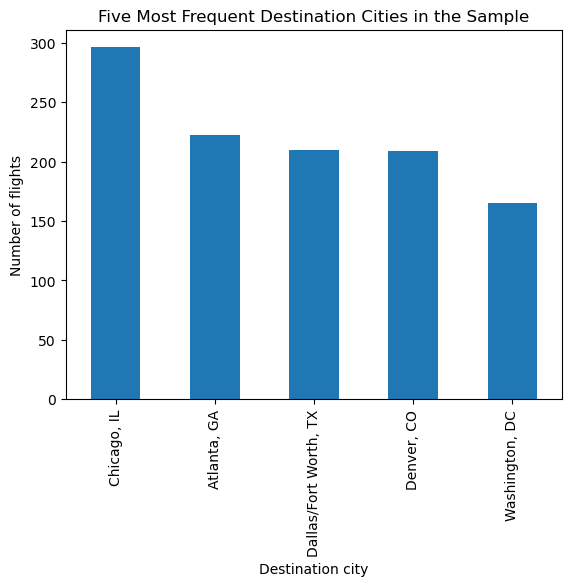

In [62]:
destination_counts = flights["destination_city"].value_counts()
top_destinations = destination_counts.head(5)
top_destinations.plot(kind="bar")
plt.title("Five Most Frequent Destination Cities in the Sample")
plt.xlabel("Destination city")
plt.ylabel("Number of flights")
plt.show()


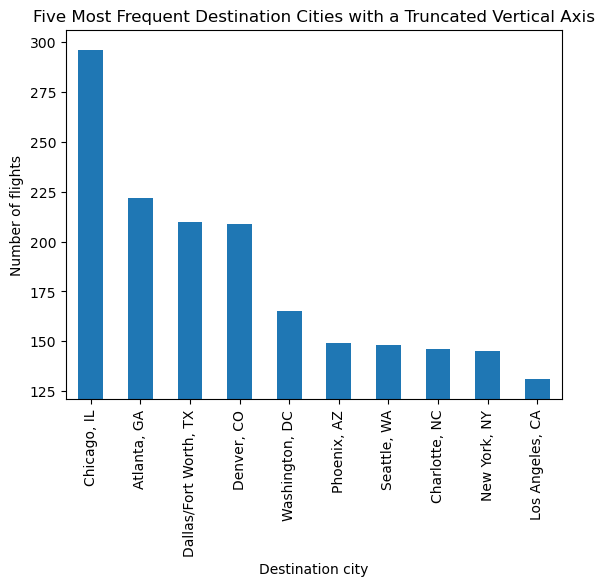

In [60]:
top_destinations.plot(kind="bar")
plt.ylim(top_destinations.min() - 10, top_destinations.max() + 10)
plt.title("Five Most Frequent Destination Cities with a Truncated Vertical Axis")
plt.xlabel("Destination city")
plt.ylabel("Number of flights")
plt.show()


**How does the truncated axis change the apparent differences among the destination cities?**

Your answer:The truncated axis makes the differences among the destination cities appear larger than they really are


**Which chart communicates the counts more honestly?**

Your answer:The chart with the vertical axis starting at zero communicates the counts more honestly

## Is this sample representative?

Review the dataset description at the top of the lab before answering these questions.


**What time period is represented by the source data?**

Your answer: arrival_delay_minutes


**Which flights were eligible to be included in the sample?**

Your answer: non stop flights


**Which flights and records were excluded before the sample was selected?**

Your answer: Canceled flights, diverted flights, and records missing any selected feature were excluded before the sample was drawn


**Does finding no missing values in the sample prove that the original BTS data had no missing values?**

Your answer: No


**Why should conclusions from this sample not automatically be generalized to canceled or diverted flights?**

Your answer:because the dataset includes only completed, non-diverted flights. Canceled and diverted flights may have different causes, delays, and travel patterns that are not represented in this sample. Therefore, the results may not accurately describe all flights.


## Choosing a chart

Choose a histogram, bar chart, or pie chart for each question. Use the question and number of categories to justify your choice.


**Which chart would you use to show the frequency of each airline?**

Your answer: bar chart because airline names are categorical data, and bar charts make it easy to compare the number of flights for each airline.


**Which chart would you use to show what proportion of sampled flights were early, on time, and delayed? Use arrival delays below 0, equal to 0, and above 0 minutes, respectively.**

Your answer:To show the proportion of sampled flights that were early, on time, and delayed, I would use a pie chart because the categories represent parts of the whole sample.


**Which chart would you use to show the distribution of flight distances?**

Your answer: To show the distribution of flight distances, I would use a histogram. Flight distance is a quantitative variable, and a histogram is designed to display how numerical values are distributed across intervals.


## Explore a dataset of your own

Apply the same inspection and visualization process to a different dataset that interests you.

### 1. Find and describe your dataset

Start with [Kaggle Datasets](https://www.kaggle.com/datasets), the [UCI Machine Learning Repository](https://archive.ics.uci.edu/), or [Data.gov](https://catalog.data.gov/). You can also search a city or state open-data portal. Search for a topic you enjoy, such as sports, music, animals, transportation, or the environment.

Choose a manageable CSV file with a data dictionary (or equivalent feature documentation), at least one quantitative feature, and at least one categorical feature with a manageable number of categories. Use a different dataset from the flights and penguins already used in class. Save the file in this notebook's `data` folder.

Read the data dictionary before choosing your features. In a short paragraph, describe the dataset's subject, what one row represents, and its time period and geographic coverage if documented. Include its title, publisher or creator, a direct link to the dataset, and a link to the data dictionary. State when information is not documented instead of guessing.


**Dataset description and source links:**

Your answer: Iris Dataset

https://archive.ics.uci.edu/ml/datasets/Iris

### 2. Load the data and describe every feature

Load your CSV into a new DataFrame with a descriptive name ending in `_df`, such as `movies_df`, `weather_df`, or `animals_df`. Choose a name that describes your dataset and use it consistently throughout your analysis. Display its first five rows, shape, `.info()`, and `.isnull().sum()` to inspect its features, storage types, and missing values. Use a relative path so your notebook can run on another computer.


In [74]:
import pandas as pd

iris_df = pd.read_csv(
    r"C:\Users\james\Desktop\SIM3032\iris\iris.data",
    header=None,
    names=[
        "sepal_length",
        "sepal_width",
        "petal_length",
        "petal_width",
        "species"
    ]
)

iris_df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


Complete the table below with **one row for every feature** in your dataset. Add as many rows as needed. Use the data dictionary to summarize what each feature means, including units or category-code meanings where relevant.

- **Data type:** quantitative or categorical; identify identifiers and date/time features explicitly when appropriate. A numeric identifier is not a quantitative measurement.
- **Data storage type:** the actual Pandas dtype shown by `.info()` or `.dtypes`, such as `int64`, `float64`, `object`, `str`, or `datetime64[ns]`.
- **Missing values:** the number reported for that feature, including 0 when there are none. Count missing values before removing records. If the dictionary defines special missing codes, such as -999 or "Unknown", explain how you handle those codes and make sure the counts reflect that decision.


| Feature | Description from the data dictionary (including units/codes) | Data type | Data storage type | Number of missing values |
| -sepal_length- | sepal_width| petal_length | petal_width | species |
| Length of the sepal in centimeters (cm) | Width of the sepal in centimeters (cm) | Length of the petal in centimeters (cm) | Width of the petal in centimeters (cm) | Species of iris flower (Iris-setosa, Iris-versicolor, or Iris-virginica) |

**Missing-value codes or other data preparation, if applicable:**

Your answer:Feature	Description	Data Type	Pandas Storage Type	Missing Valuessepal_length	Length of the sepal in centimeters (cm)	Quantitative	float64	0
sepal_width	Width of the sepal in centimeters (cm)	Quantitative	float64	0
petal_length	Length of the petal in centimeters (cm)	Quantitative	float64	0
petal_width	Width of the petal in centimeters (cm)	Quantitative	float64	0
species	Species of iris flower (Iris-setosa, Iris-versicolor, or Iris-virginica)	Categorical	object	0


### 3. Visualize one quantitative feature

Choose one quantitative measurement and create an appropriate visualization of its distribution, such as a histogram. Include a descriptive title, a horizontal-axis label naming the feature and its units, and a vertical-axis label explaining what the heights represent. Explain any excluded missing values or other filtering. Do not use an ID number as your quantitative feature.


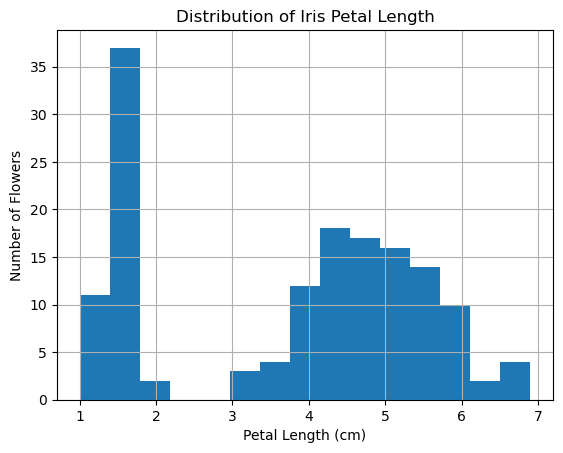

In [75]:
iris_df["petal_length"].hist(bins=15)

plt.title("Distribution of Iris Petal Length")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Number of Flowers")

plt.show()

**Which feature did you choose, and why is this chart appropriate?**

Your answer: I chose petal length (cm) as the quantitative feature. A histogram is appropriate because petal length is a numerical measurement, and a histogram shows how the values are distributed across different ranges of lengths.

**In at least one complete sentence, describe what the figure tells you about this feature.** Refer to a visible pattern such as typical values, range, shape, or unusual observations, using values and units where possible. Describe the observations in your dataset without assuming they represent a larger population.

Your interpretation:
The histogram shows that petal lengths in this dataset range from approximately 1 cm to 7 cm. Most flowers have petal lengths between about 1 cm and 5 cm

### 4. Visualize one categorical feature

Choose a categorical feature and create an appropriate visualization of its distribution. A bar chart of category counts is a good choice; use `.value_counts()` to obtain numeric bar heights from text labels. Include a descriptive title and labels identifying the categories and counts or percentages on the axes. If you choose a pie chart for a small number of categories, label the slices and their shares instead of axes. Explain any excluded missing values or categories, and identify the denominator if you use percentages.


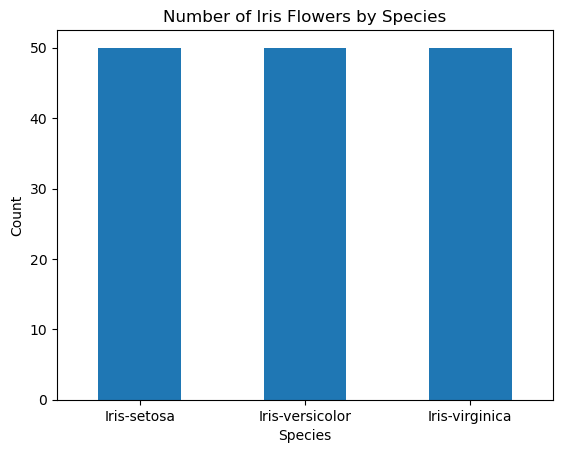

In [77]:
iris_df["species"].value_counts().plot(kind="bar")

plt.title("Number of Iris Flowers by Species")
plt.xlabel("Species")
plt.xticks(rotation=0)
plt.ylabel("Count")

plt.show()


**Which feature did you choose, and why is this chart appropriate?**

Your answer: I chose species as the categorical feature. A bar chart is appropriate because species consists of distinct categories, and a bar chart clearly shows and compares the number of observations in each category.

**In at least one complete sentence, describe what the figure tells you about this feature.** Identify a meaningful pattern, such as the most or least common category or a difference in counts or shares. Support the interpretation with evidence visible in your figure.

Your interpretation:
The bar chart shows that the three species, Iris-setosa, Iris-versicolor, and Iris-virginica, each occur about 50 times in the dataset.

## Reflect on AI assistance

Complete one of the following statements.

**If you used an AI tool:**

- Tool used: Anaconda Assisit
- What I asked it to help with: error fixing
- One suggestion I checked against my code, chart, or output: i only used it to check my output when errors occured
- What I accepted, modified, or rejected—and why:

**If you did not use an AI tool:**

- I did not use an AI tool for this assignment.
- One resource or troubleshooting strategy I used instead was:


Your response:


## Submission checklist

- All code cells run from top to bottom without errors.
- The destination-city bar chart has a descriptive title and labeled axes.
- The default, 5-bin, and 25-bin arrival-delay histograms are included and labeled.
- Both vertical-axis demonstrations are included.
- Every question has one response in its own answer cell.
- The sample questions are answered using the dataset documentation.
- The chosen dataset and its data dictionary are linked and described.
- The feature table includes a description, data type, storage type, and missing-value count for every feature.
- One quantitative and one categorical feature have appropriate labeled visualizations and at least one sentence of interpretation each.
- The chosen CSV is included in the `data` folder with the submitted notebook, and relative paths work.
- The AI-use reflection is complete and honest.
